# US Unemployment Trends

How did the number unemployed change over the recorded period?

Data: [ggplot2/economics](https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/economics.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Unemploy is a count in thousands, not an unemployment rate; population changes matter.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'US Unemployment Trends',
 'executed_utc': '2026-11-21T10:14:09.542462+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/ggplot2/economics.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/ggplot2/economics.html',
 'sha256': '4d31c9d81990272ab66ecf263d510c8ff51a744cba958c31ad823e3328a464fb',
 'raw_rows': 574,
 'analysis_rows': 574,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,574
1,date,object,0,0.0,574
2,pce,float64,0,0.0,574
3,pop,float64,0,0.0,574
4,psavert,float64,0,0.0,115
5,uempmed,float64,0,0.0,128
6,unemploy,int64,0,0.0,550


## SQL and analysis
Complete-case descriptive comparison of unemploy by date; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "date" AS segment, COUNT(*) AS rows_used, AVG("unemploy") AS metric, MIN("unemploy") AS minimum, MAX("unemploy") AS maximum FROM observations GROUP BY "date" ORDER BY "date";

The first recorded mean is 2,944.000; the last is 8,526.000. The recorded period, rather than today, defines this comparison.


,segment,rows_used,metric,minimum,maximum
0,1967-07-01 00:00:00,1,2944.0,2944,2944
1,1967-08-01 00:00:00,1,2945.0,2945,2945
2,1967-09-01 00:00:00,1,2958.0,2958,2958
3,1967-10-01 00:00:00,1,3143.0,3143,3143
4,1967-11-01 00:00:00,1,3066.0,3066,3066
5,1967-12-01 00:00:00,1,3018.0,3018,3018
6,1968-01-01 00:00:00,1,2878.0,2878,2878
7,1968-02-01 00:00:00,1,3001.0,3001,3001
8,1968-03-01 00:00:00,1,2877.0,2877,2877
9,1968-04-01 00:00:00,1,2709.0,2709,2709


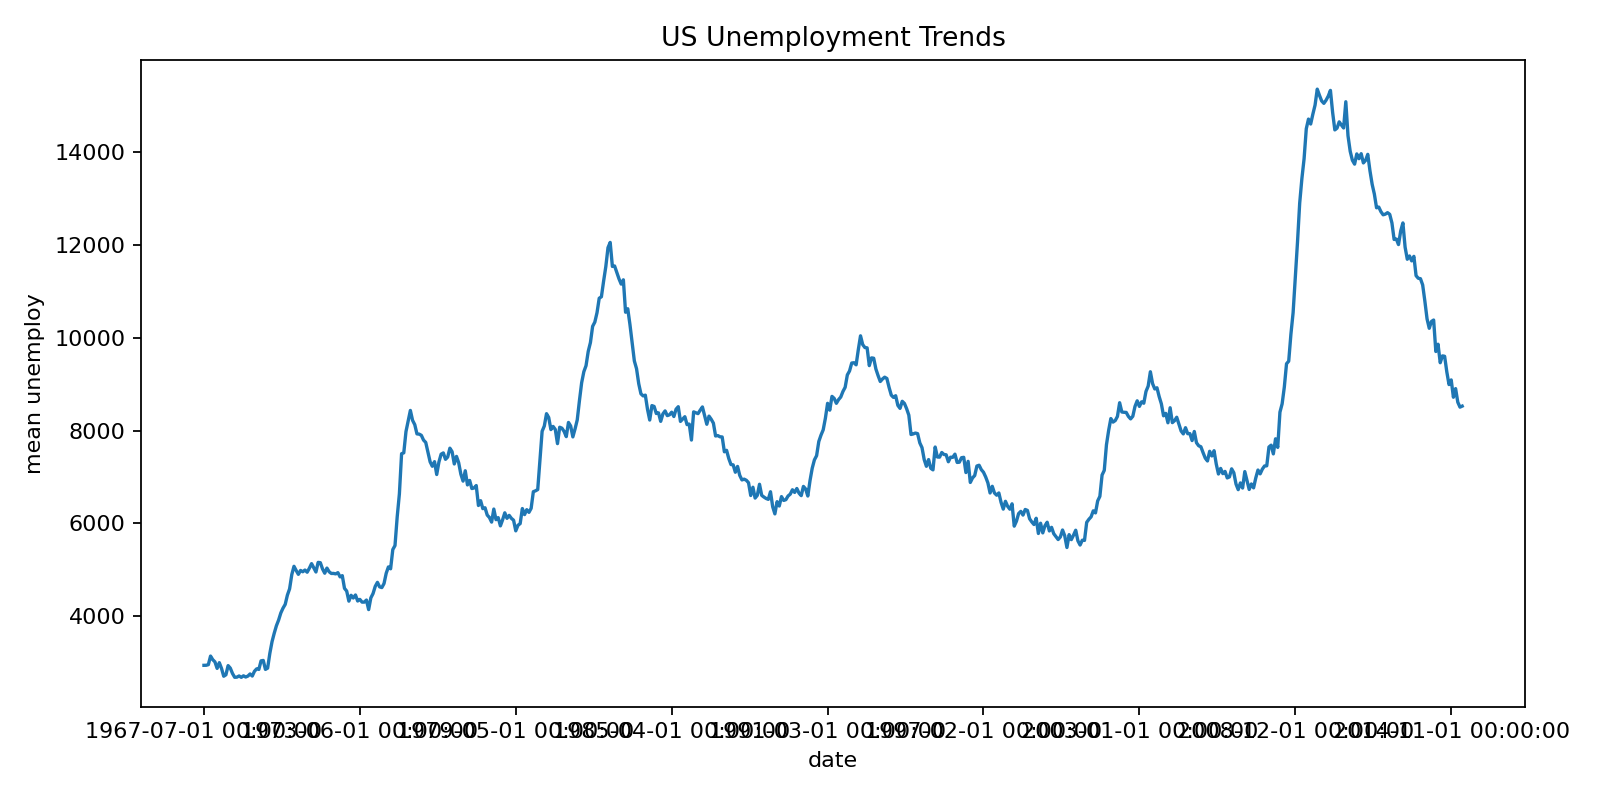

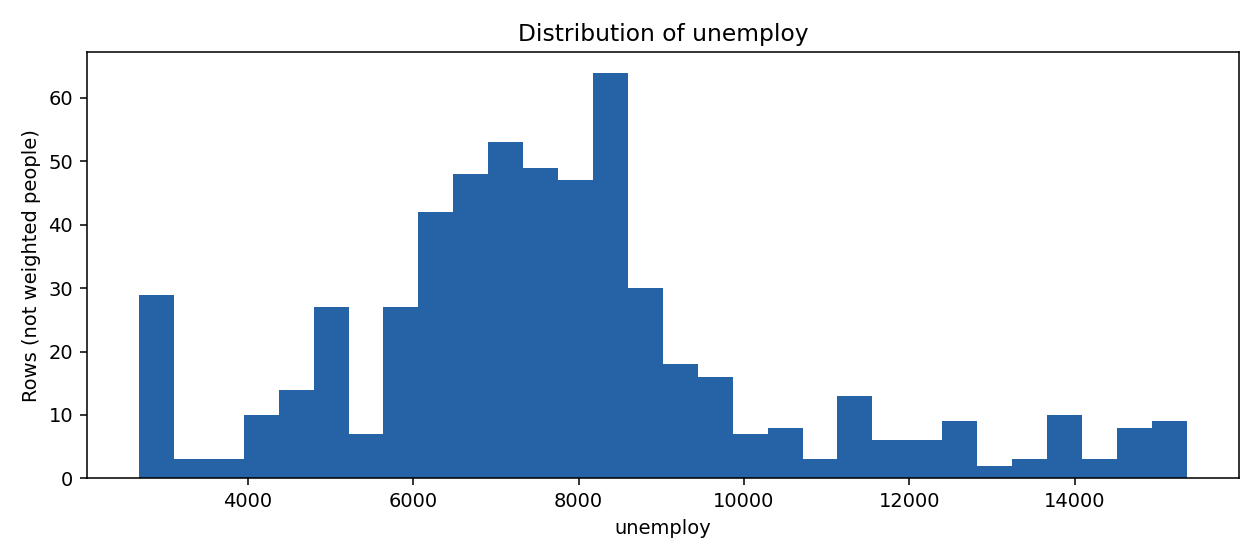

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Unemploy is a count in thousands, not an unemployment rate; population changes matter.

**Next action:** Validate turning points against official labour statistics.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.